In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from scipy.special import logit, expit

The following is analysis for just total compute stock forecasts.

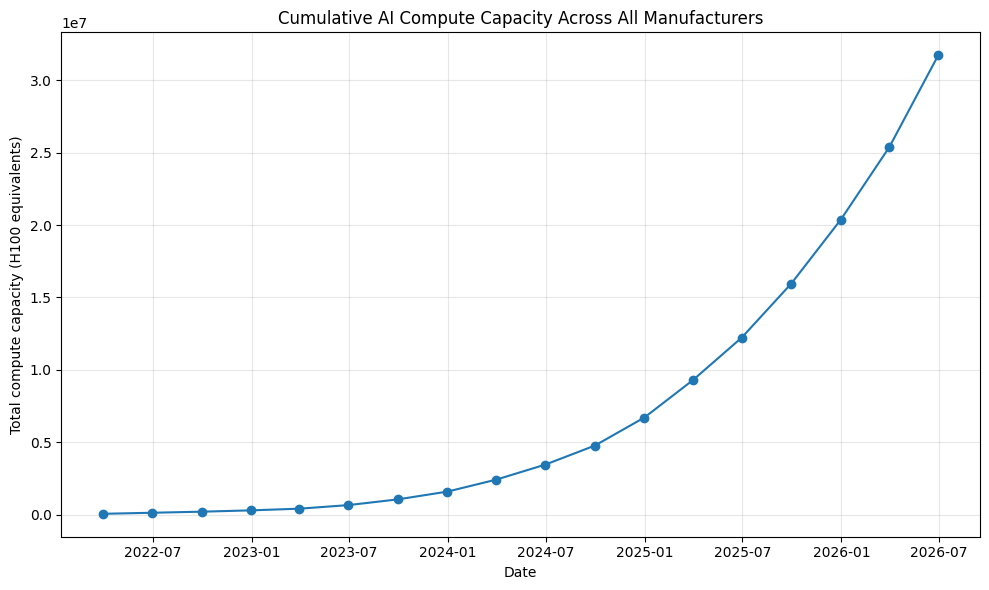

In [31]:
df = pd.read_csv("cumulative_timelines_by_designer.csv")

df["End date"] = pd.to_datetime(df["End date"])

total_compute = (
    df.groupby("End date")["Compute estimate in H100e (median)"]
    .sum()
    .reset_index()
    .rename(columns={"Compute estimate in H100e (median)": "Total compute"})
)

plt.figure(figsize=(10, 6))
plt.plot(total_compute["End date"][:-1], total_compute["Total compute"][:-1],
         marker="o")

plt.xlabel("Date")
plt.ylabel("Total compute capacity (H100 equivalents)")
plt.title("Cumulative AI Compute Capacity Across All Manufacturers")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [32]:
reg_df = total_compute.copy()
reg_df = reg_df.sort_values("End date")
reg_df = reg_df[:-1]
reg_df = reg_df[reg_df["Total compute"] > 0].copy()

reg_df["t"] = (
    reg_df["End date"] - reg_df["End date"].min()
).dt.days / 365.25

reg_df["log_compute"] = np.log(reg_df["Total compute"])

X = sm.add_constant(reg_df["t"])
y = reg_df["log_compute"]

model = sm.OLS(y, X).fit()

print(model.summary())

beta = model.params["t"]

print(f"\nExponential growth parameter: {beta:.4f} per year")
print(f"Annual growth rate: {(np.exp(beta) - 1)*100:.2f}%")

                            OLS Regression Results                            
Dep. Variable:            log_compute   R-squared:                       0.988
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     1268.
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.15e-16
Time:                        21:15:15   Log-Likelihood:                 2.6385
No. Observations:                  18   AIC:                            -1.277
Df Residuals:                      16   BIC:                            0.5037
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.5805      0.100    115.464      0.0

In [33]:
reg_df["t_squared"] = reg_df["t"] ** 2

X_linear = sm.add_constant(reg_df[["t"]])
model_linear = sm.OLS(
    reg_df["log_compute"], X_linear
).fit()

X_quad = sm.add_constant(reg_df[["t", "t_squared"]])
model_quad = sm.OLS(
    reg_df["log_compute"], X_quad
).fit()

print(model_quad.summary())


print(model_quad.t_test("t_squared = 0"))


                            OLS Regression Results                            
Dep. Variable:            log_compute   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                     7188.
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           4.31e-23
Time:                        21:15:16   Log-Likelihood:                 24.969
No. Observations:                  18   AIC:                            -43.94
Df Residuals:                      15   BIC:                            -41.27
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.2019      0.042    266.295      0.0

In [34]:
# log-quadratic model
last_date = reg_df["End date"][:-1].max()
target_date = pd.Timestamp("2030-12-31")

start_date = reg_df["End date"].min()

t0 = (last_date - start_date).days / 365.25
t1 = (target_date - start_date).days / 365.25

dt = t1 - t0
dt2 = t1**2 - t0**2

log_growth = (
    model_quad.params["t"] * dt
    + model_quad.params["t_squared"] * dt2
)

coeffs = ["t", "t_squared"]
L = np.array([dt, dt2])

cov = model_quad.cov_params().loc[coeffs, coeffs].to_numpy()
se = np.sqrt(L @ cov @ L)

z = (log_growth - np.log(9)) / se
p_value = 2 * norm.sf(abs(z))

# 95% confidence interval for the growth factor
ci_lower = np.exp(log_growth - 1.96 * se)
ci_upper = np.exp(log_growth + 1.96 * se)

print(f"Last observation: {last_date.date()}")
print(f"Target date: {target_date.date()}")
print(f"95% CI: [{ci_lower:.2f}x, {ci_upper:.2f}x]")
print(f"p-value: {p_value:.3e}")


Last observation: 2026-03-31
Target date: 2030-12-31
95% CI: [1.79x, 9.49x]
p-value: 6.638e-02


In [35]:
# pure exponential model
last_date = reg_df["End date"][:-1].max()
target_date = pd.Timestamp("2030-12-31")
start_date = reg_df["End date"].min()

t0 = (last_date - start_date).days / 365.25
t1 = (target_date - start_date).days / 365.25
dt = t1 - t0

# Predicted log growth under exponential model
log_growth = model.params["t"] * dt

# Standard error using coefficient covariance
se = np.sqrt(
    dt**2 * model.cov_params().loc["t", "t"]
)

# Wald test: H0 = 9x growth
z = (log_growth - np.log(9)) / se
p_value = 2 * norm.sf(abs(z))

# 95% confidence interval for growth factor
ci_lower = np.exp(log_growth - 1.96 * se)
ci_upper = np.exp(log_growth + 1.96 * se)

print(f"Last observation: {last_date.date()}")
print(f"Target date: {target_date.date()}")
print(f"95% CI: [{ci_lower:.2f}x, {ci_upper:.2f}x]")
print(f"p-value: {p_value:.3e}")

Last observation: 2026-03-31
Target date: 2030-12-31
95% CI: [626.77x, 1327.26x]
p-value: 1.217e-128


The following performs similar statistical analysis for compute per chip forecasts. 

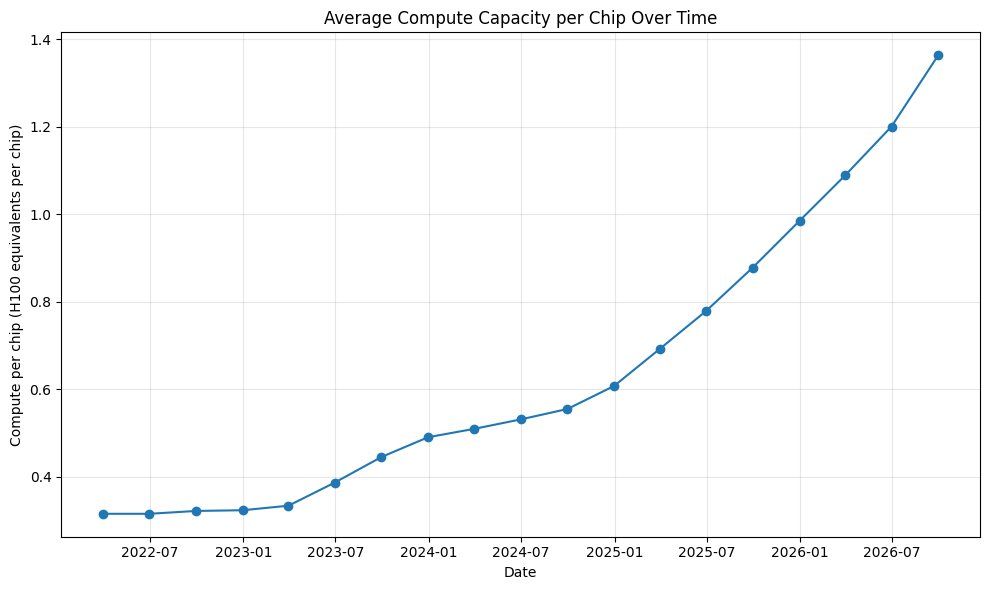

In [23]:
df["End date"] = pd.to_datetime(df["End date"])

chip_data = (
    df.groupby("End date")
    .agg({
        "Compute estimate in H100e (median)": "sum",
        "Number of units (median)": "sum"
    })
    .reset_index()
    .sort_values("End date")
)
chip_data["Compute per chip"] = (
    chip_data["Compute estimate in H100e (median)"]
    / chip_data["Number of units (median)"]
)

plt.figure(figsize=(10, 6))

plt.plot(
    chip_data["End date"],
    chip_data["Compute per chip"],
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Compute per chip (H100 equivalents per chip)")
plt.title("Average Compute Capacity per Chip Over Time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


                            OLS Regression Results                            
Dep. Variable:            log_compute   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                     734.8
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.08e-15
Time:                        20:45:36   Log-Likelihood:                 30.705
No. Observations:                  18   AIC:                            -55.41
Df Residuals:                      15   BIC:                            -52.74
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.2087      0.031    -39.517      0.0

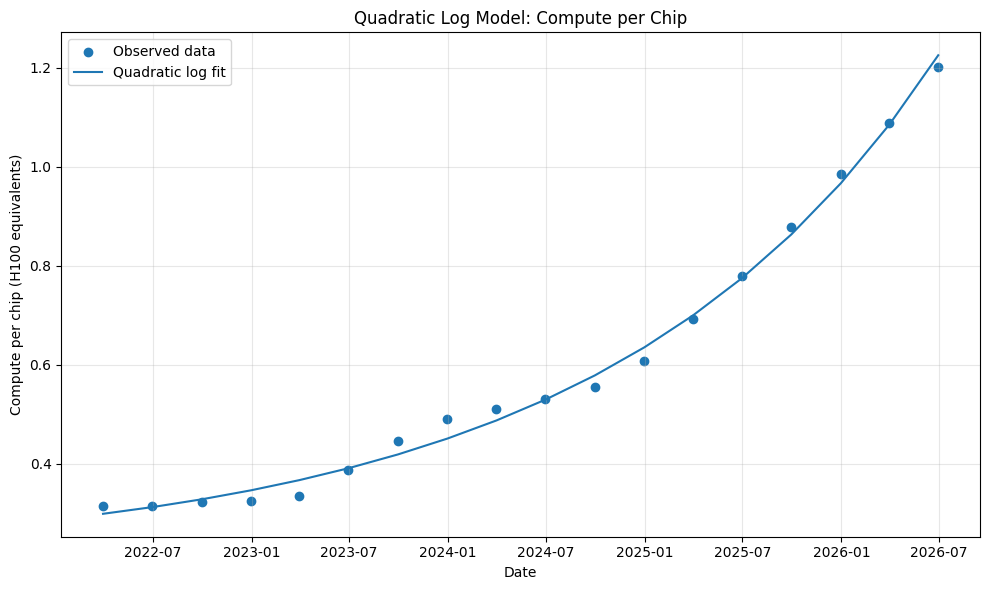

In [24]:
chip_reg = chip_data.copy().sort_values("End date")
chip_reg = chip_reg[chip_reg["Compute per chip"] > 0].copy()
chip_reg = chip_reg[:-1]

chip_reg["t"] = (
    chip_reg["End date"] - chip_reg["End date"].min()
).dt.days / 365.25

chip_reg["t_squared"] = chip_reg["t"] ** 2
chip_reg["log_compute"] = np.log(chip_reg["Compute per chip"])

# Fit quadratic log model
X = sm.add_constant(chip_reg[["t", "t_squared"]])
y = chip_reg["log_compute"]

model_quad_chip = sm.OLS(y, X).fit()

print(model_quad_chip.summary())

plt.figure(figsize=(10, 6))

plt.scatter(
    chip_reg["End date"],
    chip_reg["Compute per chip"],
    label="Observed data"
)

plt.plot(
    chip_reg["End date"],
    np.exp(model_quad_chip.predict(X)),
    label="Quadratic log fit"
)

plt.xlabel("Date")
plt.ylabel("Compute per chip (H100 equivalents)")
plt.title("Quadratic Log Model: Compute per Chip")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:
last_date = chip_reg["End date"][:-1].max()
target_date = pd.Timestamp("2030-12-31")
start_date = chip_reg["End date"].min()

t0 = (last_date - start_date).days / 365.25
t1 = (target_date - start_date).days / 365.25

dt = t1 - t0
dt2 = t1**2 - t0**2

log_growth = (
    model_quad_chip.params["t"] * dt
    + model_quad_chip.params["t_squared"] * dt2
)

coeffs = ["t", "t_squared"]
L = np.array([dt, dt2])

cov = model_quad_chip.cov_params().loc[coeffs, coeffs].to_numpy()
se = np.sqrt(L @ cov @ L)

z = (log_growth - np.log(20)) / se
p_value = 2 * norm.sf(abs(z))

ci_lower = np.exp(log_growth - 1.96 * se)
ci_upper = np.exp(log_growth + 1.96 * se)

print(f"Last observation: {last_date.date()}")
print(f"Target date: {target_date.date()}")
print(f"95% CI: [{ci_lower:.2f}x, {ci_upper:.2f}x]")
print(f"p-value: {p_value:.3e}")


Last observation: 2026-03-31
Target date: 2030-12-31
95% CI: [12.79x, 42.97x]
p-value: 6.069e-01


Looking at how performance scales with compute for different tasks.

                            OLS Regression Results                            
Dep. Variable:         logit_accuracy   R-squared:                       0.562
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     11.56
Date:                Wed, 04 Nov 2026   Prob (F-statistic):            0.00788
Time:                        22:35:20   Log-Likelihood:                -16.053
No. Observations:                  11   AIC:                             36.11
Df Residuals:                       9   BIC:                             36.90
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.4386      0.374     -3.848      

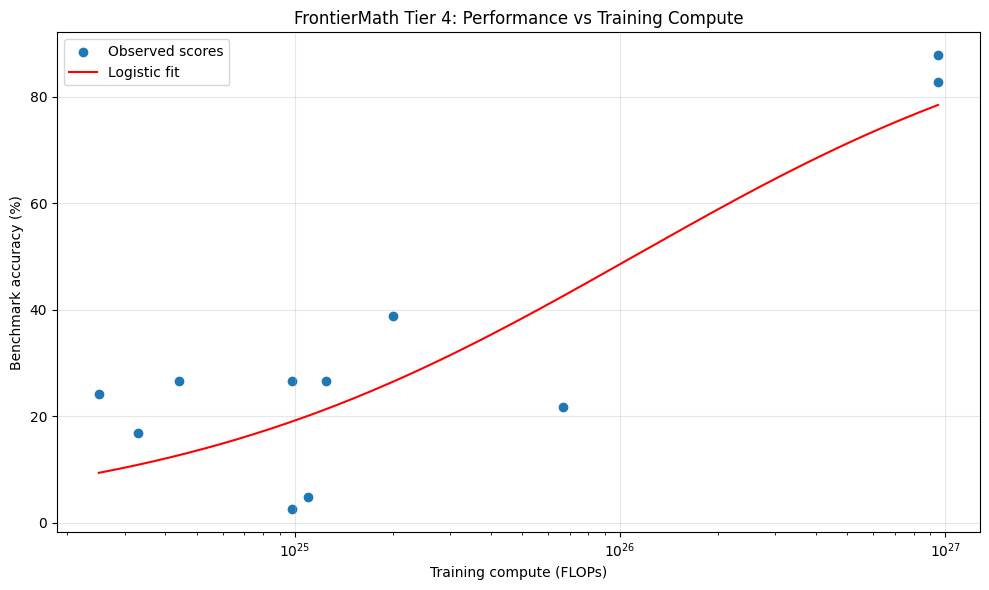

In [5]:
compute = np.array([
    2.5e24, 3.3e24, 4.4e24,
    9.8e24, 9.8e24, 1.1e25,
    1.25e25, 2.0e25, 6.7e25,
    9.5e26, 9.5e26
])

accuracy = np.array([
    0.241, 0.168, 0.266,
    0.025, 0.266, 0.048,
    0.266, 0.388, 0.218,
    0.828, 0.878
])

df_bench = pd.DataFrame({
    "compute": compute,
    "accuracy": accuracy
})

df_bench["log_compute"] = np.log(
    df_bench["compute"] / 1e25
)

df_bench["logit_accuracy"] = logit(df_bench["accuracy"])

X = sm.add_constant(df_bench["log_compute"])
y = df_bench["logit_accuracy"]

model_bench = sm.OLS(y, X).fit()

print(model_bench.summary())

beta = model_bench.params["log_compute"]
ci = model_bench.conf_int().loc["log_compute"]

print(f"\nCompute coefficient: {beta:.4f}")
print(f"95% CI: [{ci.iloc[0]:.4f}, {ci.iloc[1]:.4f}]")
print(f"p-value: {model_bench.pvalues['log_compute']:.3e}")

# Plot fitted logistic curve
compute_grid = np.logspace(
    np.log10(compute.min()),
    np.log10(compute.max()),
    300
)

X_grid = sm.add_constant(
    pd.DataFrame({
        "log_compute": np.log(compute_grid / 1e25)
    }),
    has_constant="add"
)

predicted_accuracy = expit(model_bench.predict(X_grid))

plt.figure(figsize=(10, 6))
plt.scatter(compute, accuracy * 100, label="Observed scores")
plt.plot(
    compute_grid,
    predicted_accuracy * 100,
    color="red",
    label="Logistic fit"
)

plt.xscale("log")
plt.xlabel("Training compute (FLOPs)")
plt.ylabel("Benchmark accuracy (%)")
plt.title("FrontierMath Tier 4: Performance vs Training Compute")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


                            OLS Regression Results                            
Dep. Variable:            logit_score   R-squared:                       0.423
Model:                            OLS   Adj. R-squared:                  0.396
Method:                 Least Squares   F-statistic:                     15.40
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           0.000778
Time:                        22:01:24   Log-Likelihood:                 21.329
No. Observations:                  23   AIC:                            -38.66
Df Residuals:                      21   BIC:                            -36.39
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.4826      0.021     22.695      

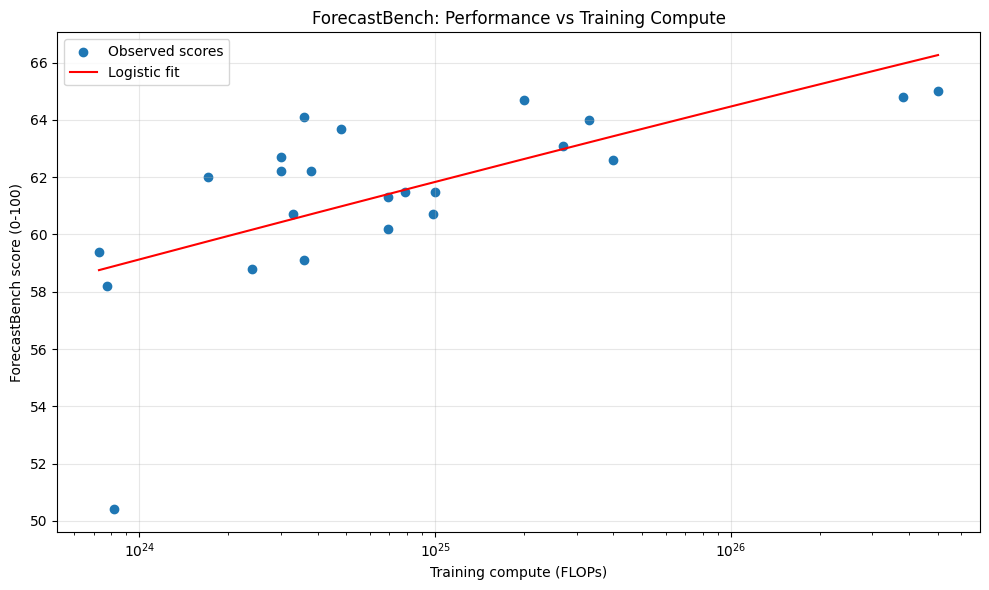

In [2]:
compute = np.array([
    7.3e23, 7.8e23, 8.2e23,
    1.7e24, 2.4e24, 3.0e24,
    3.0e24, 3.3e24, 3.6e24,
    3.6e24, 3.8e24, 4.8e24,
    6.9e24, 6.9e24, 7.9e24,
    9.8e24, 1.0e25, 2.0e25,
    2.7e25, 3.3e25, 4.0e25,
    3.8e26, 5.0e26
])

scores = np.array([
    59.4, 58.2, 50.4,
    62.0, 58.8, 62.2,
    62.7, 60.7, 59.1,
    64.1, 62.2, 63.7,
    61.3, 60.2, 61.5,
    60.7, 61.5, 64.7,
    63.1, 64.0, 62.6,
    64.8, 65.0
])

df_bench = pd.DataFrame({
    "compute": compute,
    "score": scores
})

df_bench["p"] = df_bench["score"] / 100

df_bench["p"] = df_bench["p"].clip(1e-4, 1 - 1e-4)

df_bench["log_compute"] = np.log(
    df_bench["compute"] / 1e25
)

df_bench["logit_score"] = logit(df_bench["p"])

X = sm.add_constant(df_bench["log_compute"])
y = df_bench["logit_score"]

model_forecast = sm.OLS(y, X).fit()

print(model_forecast.summary())

beta = model_forecast.params["log_compute"]
ci = model_forecast.conf_int().loc["log_compute"]

print(f"\nCompute coefficient: {beta:.4f}")
print(f"95% CI: [{ci.iloc[0]:.4f}, {ci.iloc[1]:.4f}]")
print(f"p-value: {model_forecast.pvalues['log_compute']:.3e}")

compute_grid = np.logspace(
    np.log10(compute.min()),
    np.log10(compute.max()),
    300
)

X_grid = sm.add_constant(
    pd.DataFrame({
        "log_compute": np.log(compute_grid / 1e25)
    }),
    has_constant="add"
)

predicted_scores = 100 * expit(
    model_forecast.predict(X_grid)
)

plt.figure(figsize=(10, 6))
plt.scatter(compute, scores, label="Observed scores")
plt.plot(
    compute_grid,
    predicted_scores,
    color="red",
    label="Logistic fit"
)

plt.xscale("log")
plt.xlabel("Training compute (FLOPs)")
plt.ylabel("ForecastBench score (0-100)")
plt.title("ForecastBench: Performance vs Training Compute")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()